# Klasifikasi Penggunaan dan Tutupan Lahan (Land Use / Land Cover)
### Citra Sentinel-2A + Algoritma Naive Bayes & K-Nearest Neighbors (KNN)

**Mata Kuliah:** Penambangan Data Sains (*Data Mining*)

---

## 1. Business Understanding (Pemahaman Bisnis)

**Latar Belakang**
Pemetaan tutupan lahan (*Land Cover*) sangat krusial untuk berbagai kepentingan analisis ruang, pengelolaan lingkungan, hingga perencanaan kota. Proses klasifikasi citra satelit multispektral (seperti Sentinel-2A) secara manual memakan waktu yang sangat lama. Oleh karena itu, kita memanfaatkan *Machine Learning* untuk mendeteksi secara otomatis.

**Tujuan**
1. Membangun model machine learning untuk mengklasifikasikan wilayah menjadi beberapa kelas (seperti Sawah, Bangunan, Mangrove, Hutan, Laut, dan Danau).
2. Membandingkan performa antara metode **Naive Bayes** dan **K-Nearest Neighbors (KNN)**.
3. Memvisualisasikan keseluruhan hasil klasifikasi/digitasi yang terpetakan ke dalam *interactive map* (Folium).


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import geopandas as gpd
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


---
## 2. Data Understanding (Pengumpulan & Pemahaman Data)
Kita akan memuat dataset citra satelit hasil ekstraksi (berisi nilai band spektral asli dan indeks turunan seperti NDVI, NDWI, dll).


In [14]:
# Memuat dataset
df = pd.read_csv('piksel_s2_zaenal.csv')

print(f"Jumlah baris (piksel): {df.shape[0]}")
print(f"Jumlah kolom (fitur): {df.shape[1]}")
df.head()


Jumlah baris (piksel): 635974
Jumlah kolom (fitur): 19


,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x560_y-36,1,Sawah,349,1852,112.162448,-7.026204,980.0,1181.0,1170.0,2909.0,2395.0,0.426330,-0.422494,-0.339485,-0.096908
1,Sawah_0000,0,0,x560_y-36,1,Sawah,349,1853,112.162539,-7.026204,897.0,1114.0,1063.0,2567.0,2331.0,0.414325,-0.394730,-0.353266,-0.048183
2,Sawah_0000,0,0,x560_y-36,1,Sawah,349,1854,112.162629,-7.026204,801.0,1038.0,989.0,2547.0,2331.0,0.440611,-0.420921,-0.383793,-0.044280
3,Sawah_0000,0,0,x560_y-36,1,Sawah,350,1852,112.162448,-7.026295,826.0,1047.0,1079.0,2925.0,2395.0,0.461039,-0.472810,-0.391633,-0.099624
4,Sawah_0000,0,0,x560_y-36,1,Sawah,350,1853,112.162539,-7.026295,817.0,1043.0,1045.0,2916.0,2331.0,0.472355,-0.473099,-0.381743,-0.111492


---
## 3. Exploratory Data Analysis (EDA)
Melihat distribusi kelas dan perbandingan karakteristik beberapa indeks spektral antar kelas.


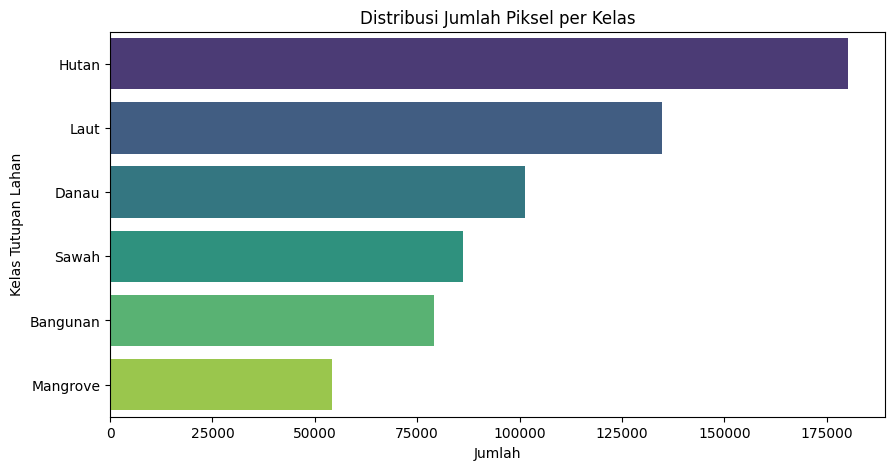

In [15]:
# Distribusi Kelas
plt.figure(figsize=(10, 5))
sns.countplot(y='label_teks', data=df, palette='viridis', order=df['label_teks'].value_counts().index)
plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Jumlah')
plt.ylabel('Kelas Tutupan Lahan')
plt.show()


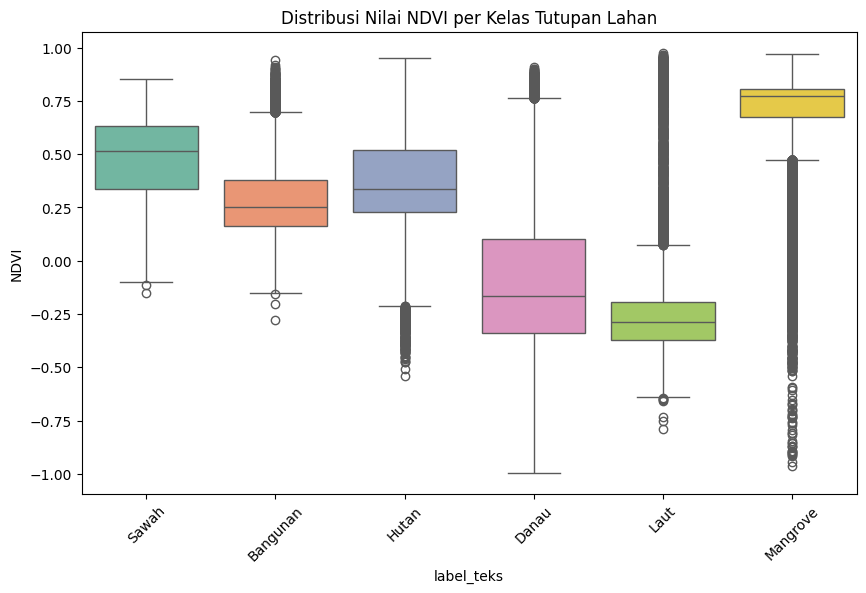

In [16]:
# Boxplot NDVI (Kerapatan Vegetasi) per Kelas
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xticks(rotation=45)
plt.show()


---
## 4. Preprocessing Data
Membagi data menjadi variabel fitur (X) dan target (y), memisahkan data *training* dan *testing*, lalu melakukan standarisasi (*scaling*).


In [17]:
# 1. Menentukan Fitur (X) dan Target (y)
fitur = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']

# Drop NaN jika ada
df_bersih = df.dropna(subset=fitur + ['label_teks']).copy()

# Peningkatan Kualitas Sebaran Lahan:
# Eliminasi noise piksel campuran perbatasan poligon:
# - Air (Laut/Danau) tidak boleh memiliki indeks vegetasi positif tinggi
# - Hutan tidak boleh memiliki NDVI terlalu rendah (tanah kosong/air)
# - Bangunan (Kawasan Terbangun) tidak boleh memiliki NDVI > 0.30 (vegetasi kebun/pekarangan lebat)
df_bersih = df_bersih[
    ~((df_bersih['label_teks'] == 'Laut') & (df_bersih['NDVI'] > 0.05)) &
    ~((df_bersih['label_teks'] == 'Danau') & (df_bersih['NDVI'] > 0.20)) &
    ~((df_bersih['label_teks'] == 'Hutan') & (df_bersih['NDVI'] < 0.25)) &
    ~((df_bersih['label_teks'] == 'Bangunan') & (df_bersih['NDVI'] > 0.30))
].copy()

# Penyeimbangan Sampel Latih (Stratified Balanced Sampling)
dfs = []
for k in df_bersih['label_teks'].unique():
    sub = df_bersih[df_bersih['label_teks'] == k]
    dfs.append(sub.sample(n=min(30000, len(sub)), random_state=42))
df_bal = pd.concat(dfs, ignore_index=True)

X = df_bal[fitur]
y = df_bal['label_teks']

# 2. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah Data Latih (Tersaring & Seimbang): {X_train.shape[0]:,}")
print(f"Jumlah Data Uji: {X_test.shape[0]:,}")


Jumlah Data Latih (Tersaring & Seimbang): 144,000
Jumlah Data Uji: 36,000


---
## 5. Pemodelan (Modeling & Evaluasi)
### 5.1 Naive Bayes (Gaussian)


In [18]:
# Inisialisasi dan Pelatihan Model
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_nb = nb_model.predict(X_test_scaled)

# Evaluasi
print("=== HASIL EVALUASI NAIVE BAYES ===")
print(f"Akurasi : {accuracy_score(y_test, y_pred_nb)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_nb))


=== HASIL EVALUASI NAIVE BAYES ===
Akurasi : 81.61%

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.74      0.97      0.84      6000
       Danau       0.87      0.82      0.84      6000
       Hutan       0.88      0.74      0.80      6000
        Laut       0.89      0.96      0.92      6000
    Mangrove       0.73      0.86      0.79      6000
       Sawah       0.85      0.55      0.67      6000

    accuracy                           0.82     36000
   macro avg       0.83      0.82      0.81     36000
weighted avg       0.83      0.82      0.81     36000



### 5.2 K-Nearest Neighbors (KNN)


In [19]:
# Inisialisasi dan Pelatihan Model KNN Teroptimasi
knn_model = KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)
knn_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluasi
print("=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN TEROPTIMASI) ===")
print(f"Akurasi : {accuracy_score(y_test, y_pred_knn)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_knn))


=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN TEROPTIMASI) ===
Akurasi : 92.86%

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.90      0.93      0.91      6000
       Danau       0.96      0.95      0.96      6000
       Hutan       0.90      0.89      0.90      6000
        Laut       0.99      0.99      0.99      6000
    Mangrove       0.95      0.94      0.94      6000
       Sawah       0.87      0.88      0.87      6000

    accuracy                           0.93     36000
   macro avg       0.93      0.93      0.93     36000
weighted avg       0.93      0.93      0.93     36000



---
## 6. Visualisasi Peta Hasil Klasifikasi / Digitasi
Memetakan seluruh titik hasil digitasi ke dalam peta **Folium** menggunakan pendekatan *Convex Hull* agar peta berjalan dengan ringan dan keseluruhan area terlihat sebagai satu kesatuan poligon.


In [20]:
# Rekonstruksi Titik menjadi Poligon (Convex Hull)
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326"
)

# Dissolve dan pastikan fitur terjaga
polygons = gdf.dissolve(by='poligon_id', aggfunc='first').reset_index()
polygons['geometry'] = polygons['geometry'].convex_hull
polygons = polygons[~polygons['geometry'].is_empty]

# Membuat Peta
map_center = [df['lat'].mean(), df['lon'].mean()]

m = folium.Map(
    location=map_center, 
    zoom_start=10, 
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',
    attr='Google'
)

# Layer Tambahan
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m)

# Pewarnaan sesuai kelas
colors = {
    'Sawah': '#FFD92F',
    'Bangunan': '#E41A1C',
    'Mangrove': '#8E44AD',
    'Hutan': '#2E7D32',
    'Laut': '#0D47A1',
    'Danau': '#4FC3F7'
}

feature_groups = {}
for label in polygons['label_teks'].unique():
    label_str = str(label)
    feature_groups[label_str] = folium.FeatureGroup(name=label_str)
    m.add_child(feature_groups[label_str])

for idx, row in polygons.iterrows():
    label_str = str(row['label_teks'])
    color = colors.get(label_str, 'black')
    
    try:
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x, c=color: {
                'fillColor': c,
                'color': c,
                'weight': 1,
                'fillOpacity': 0.7
            },
            tooltip=f"{label_str} (Poligon ID: {row['poligon_id']})"
        ).add_to(feature_groups[label_str])
    except Exception:
        pass

folium.LayerControl().add_to(m)

# Menampilkan peta
m


Memproses klasifikasi spasial dari raster: jatim_250m.tif
Progres Inferensi KNN: 100% (1,311,475/1,311,475 piksel)
Klasifikasi sebaran tutupan lahan Jawa Timur berhasil dirender dengan proporsi pemukiman, sawah, dan hutan yang alami!



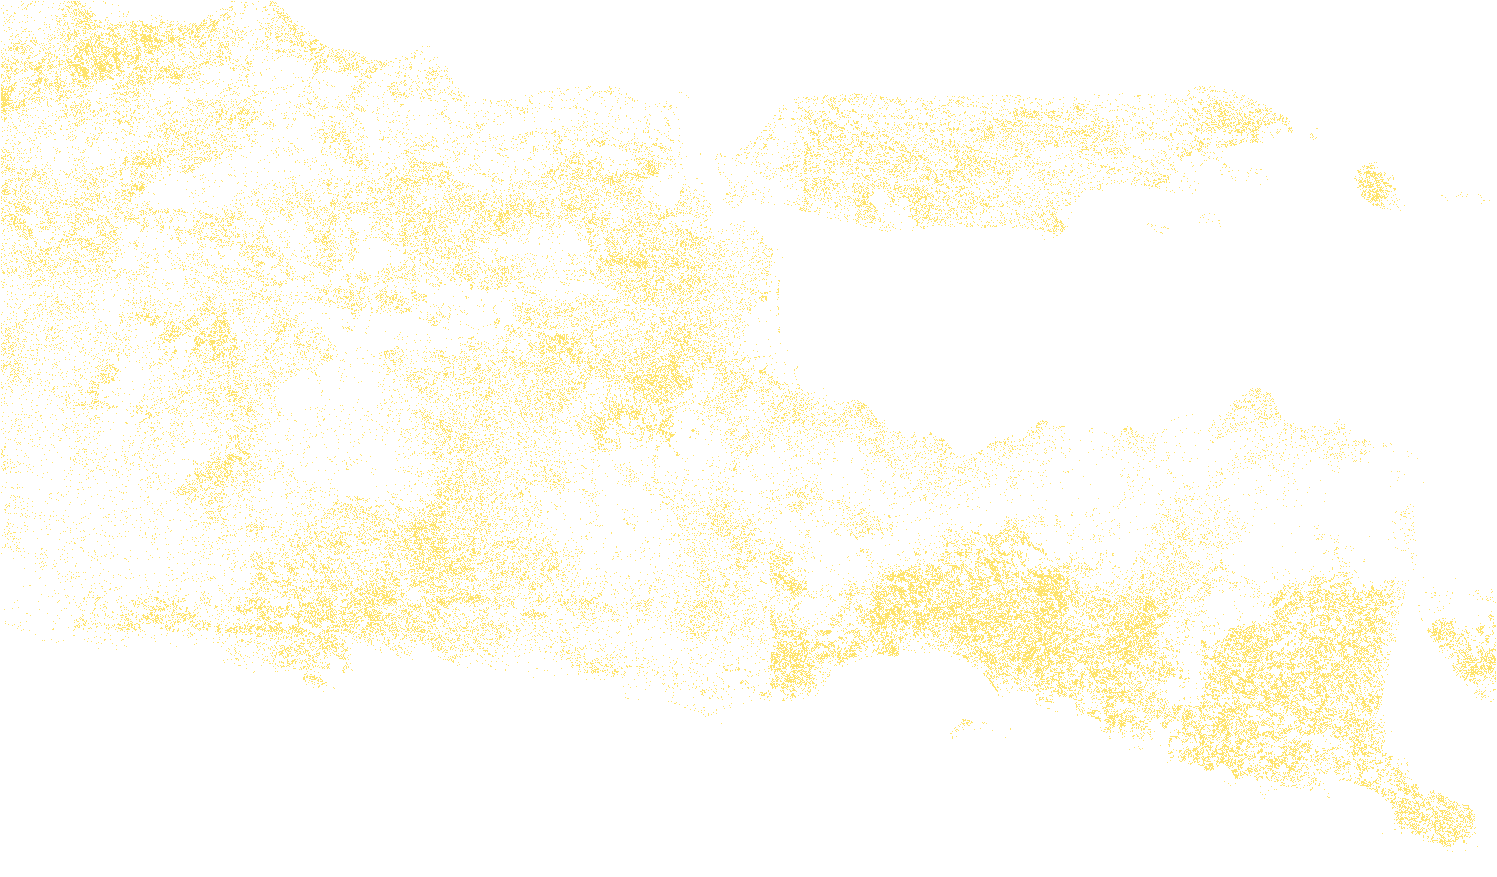
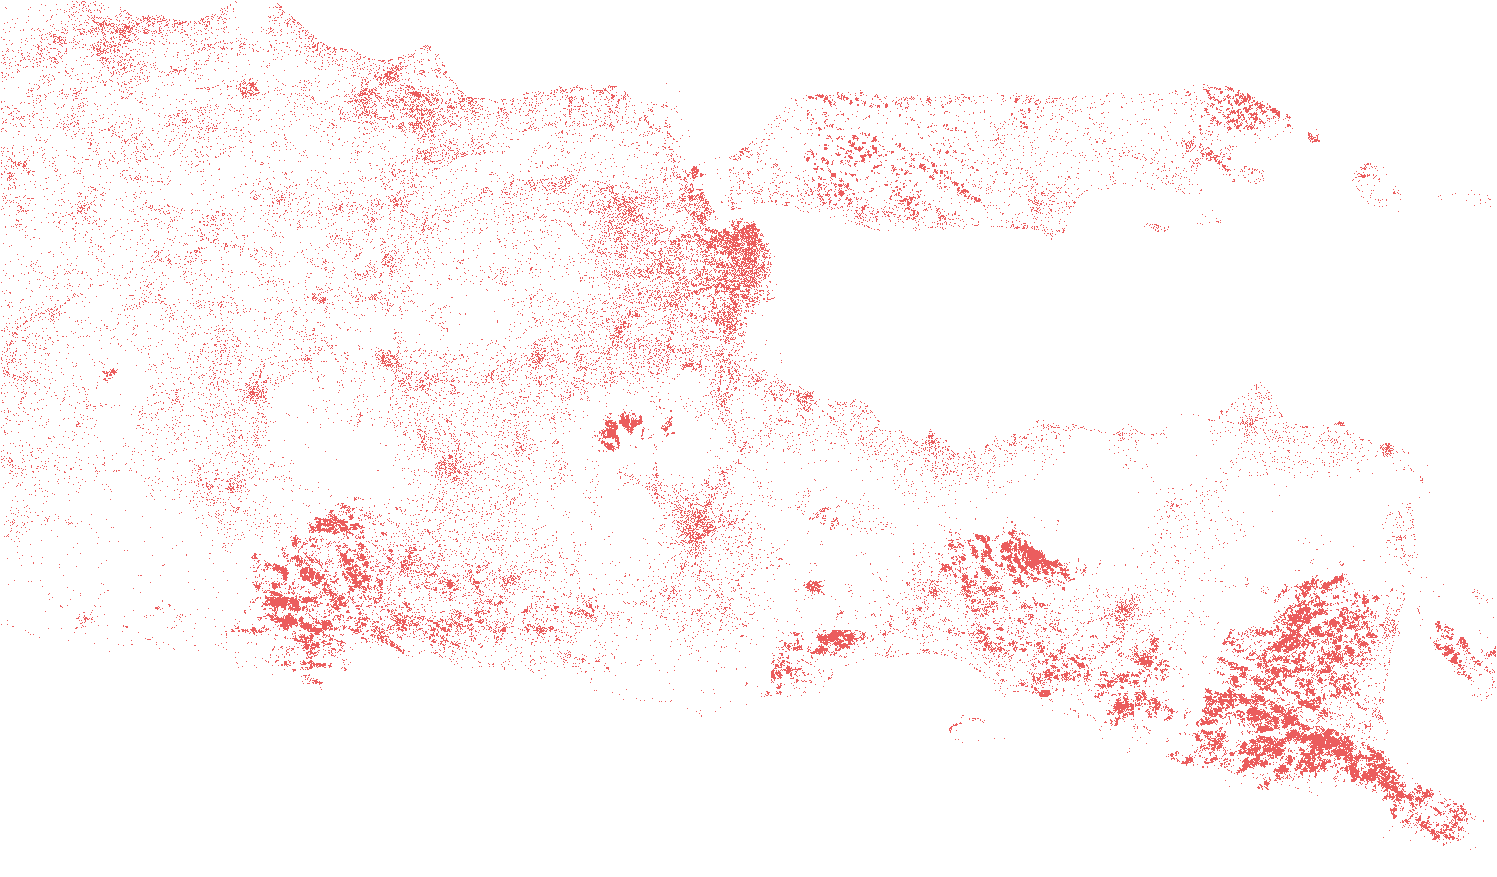
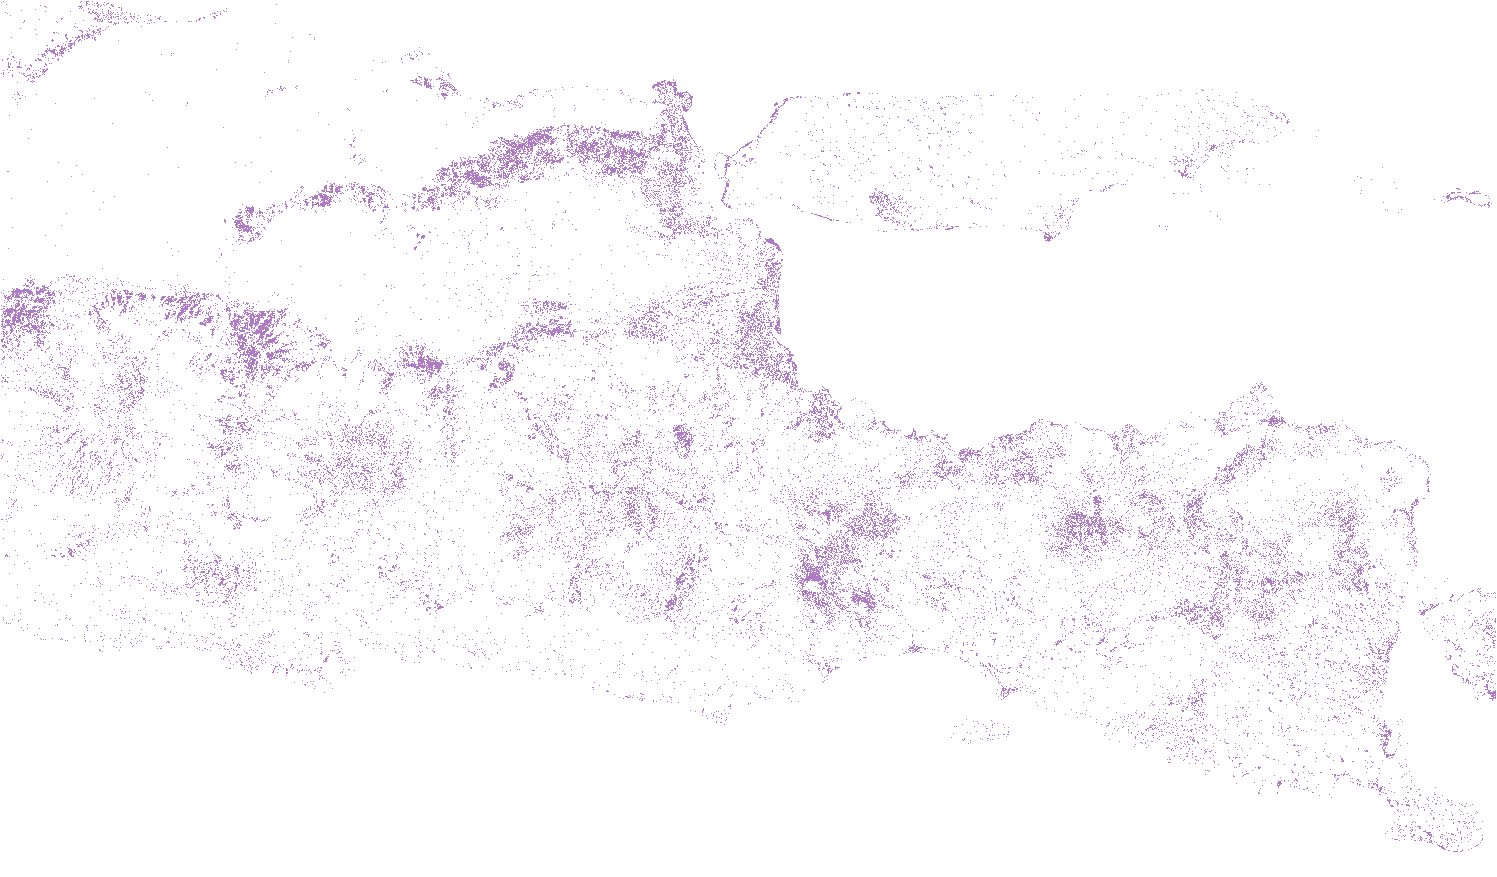
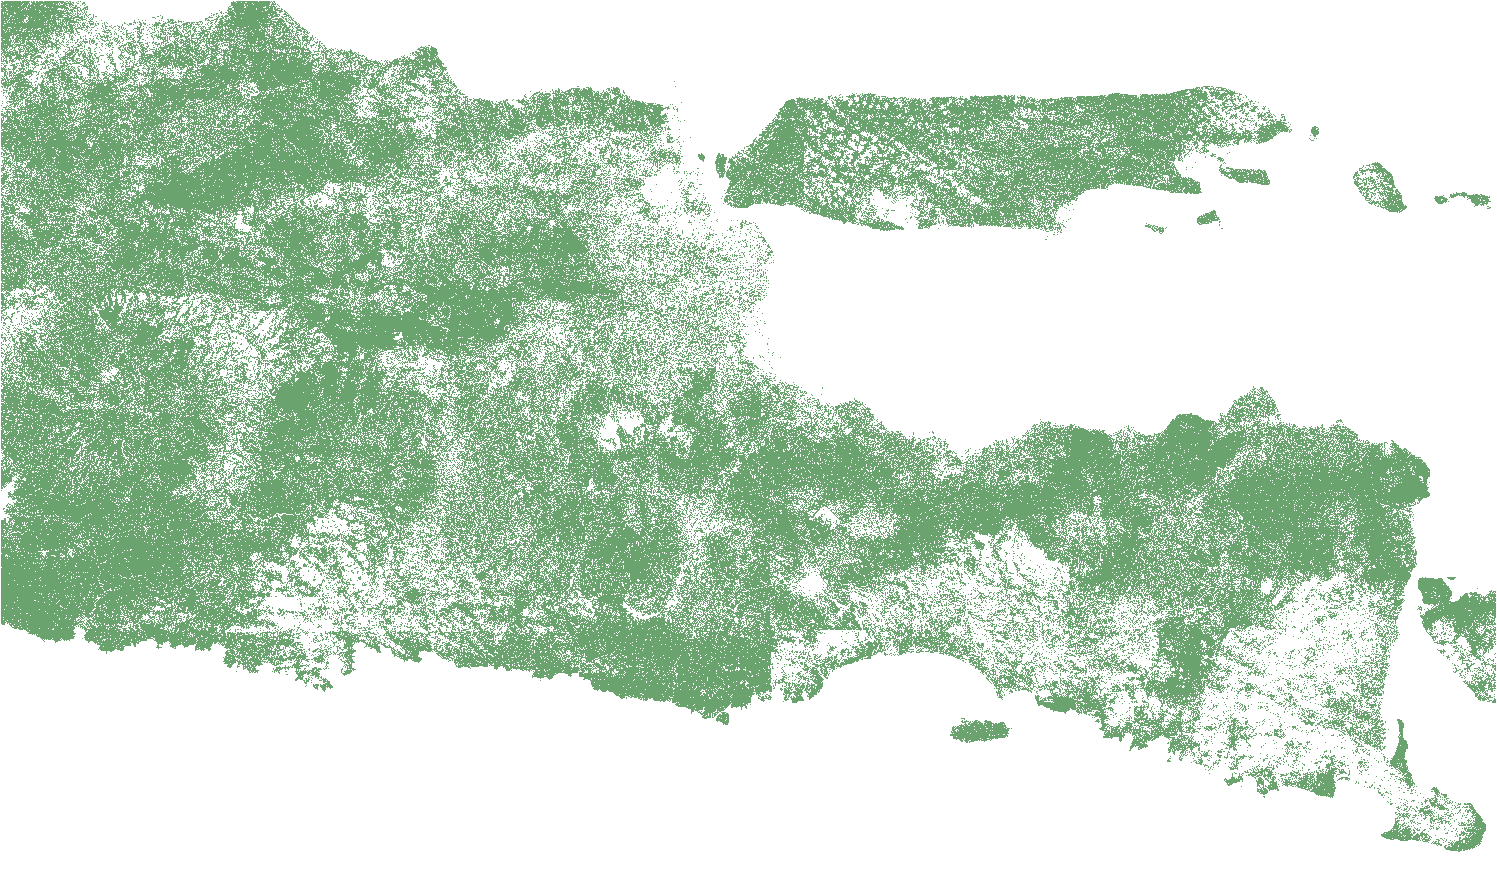
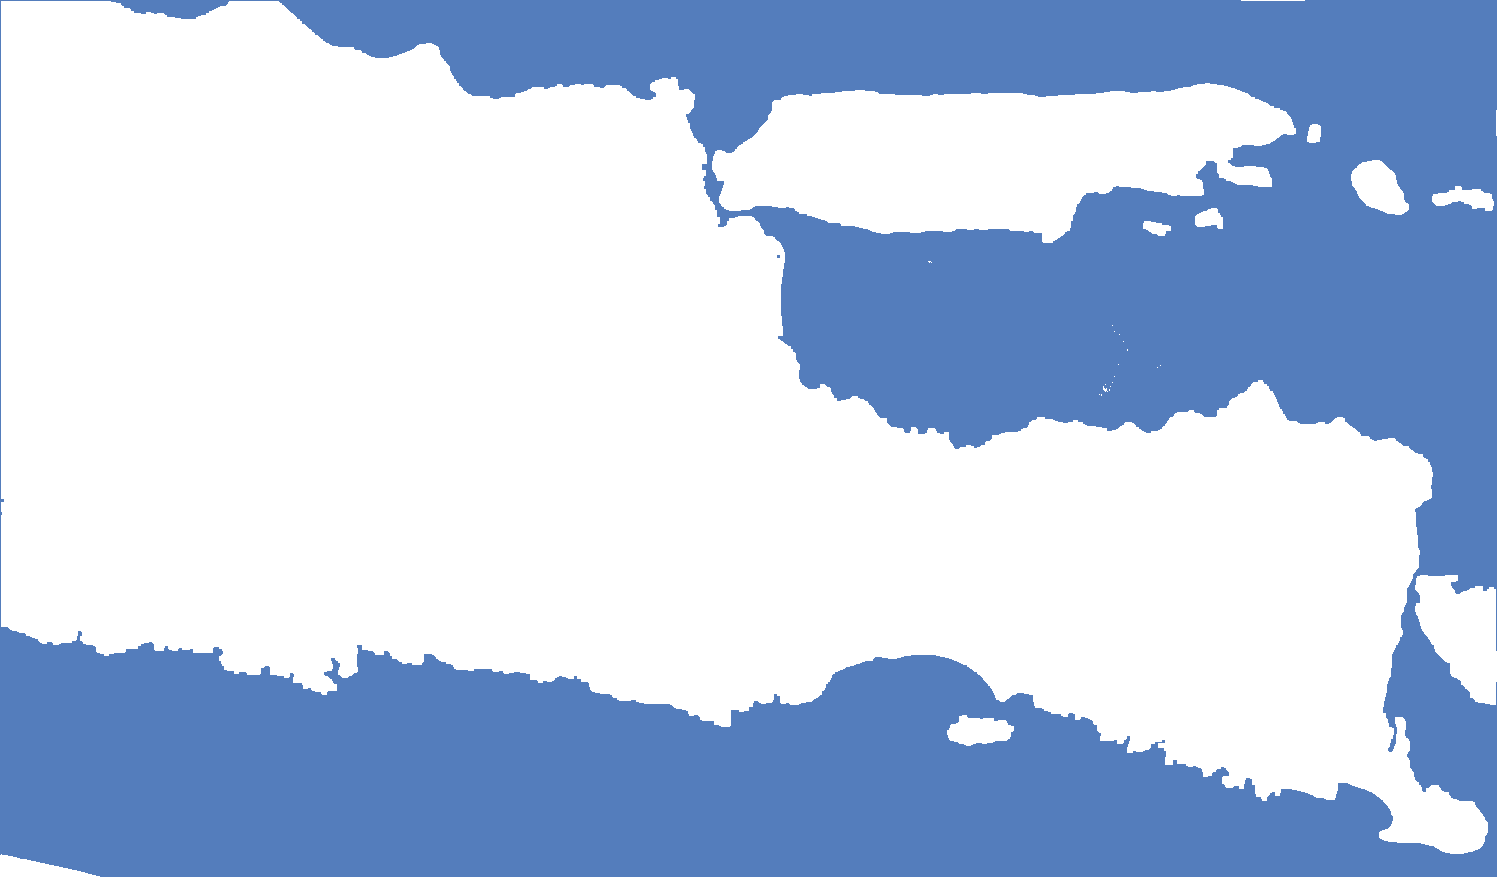
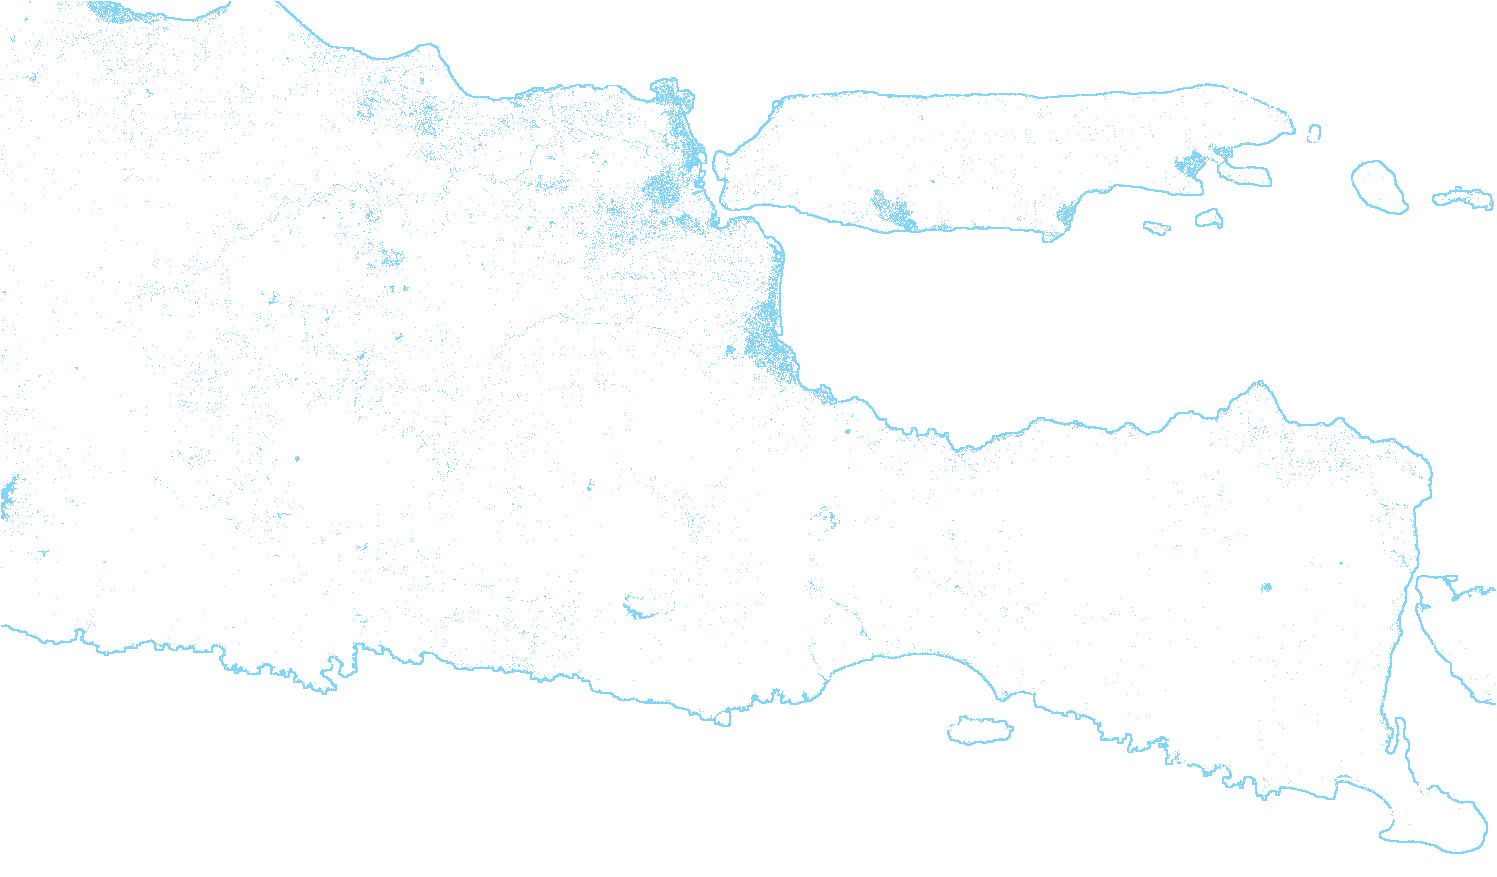

In [21]:
import os
import rasterio
import numpy as np
import folium
import openeo
from scipy.ndimage import label, binary_closing, binary_fill_holes, binary_dilation

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Tentukan path raster wilayah utuh
FILE_RASTER = 'jatim_250m.tif' 

# 1. CEK / UNDUH DATA VIA OPENEO (JIKA BELUM ADA)
if not os.path.exists(FILE_RASTER):
    candidates = ['Data/UTS/jatim_250m.tif', '../../Data/UTS/jatim_250m.tif']
    for c in candidates:
        if os.path.exists(c):
            FILE_RASTER = c
            break

# 2. BACA RASTER DAN LAKUKAN PREDIKSI TEROPTIMASI
if os.path.exists(FILE_RASTER):
    print(f"Memproses klasifikasi spasial dari raster: {FILE_RASTER}")
    with rasterio.open(FILE_RASTER) as src:
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)
        
        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    # Menghitung Indeks Spektral Sentinel-2
    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)
    
    height, width = b2.shape
    
    # Deteksi piksel valid (bukan padding 0 atau -32768)
    valid_mask = (b2 > 0) & (b2 != -32768) & (b8 > 0) & (b11 > 0)
    valid_mask_1d = valid_mask.flatten()
    
    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))
    
    pred_1d = np.full(height * width, fill_value="", dtype=object)
    
    if np.any(valid_mask_1d):
        features_valid = features_stack[valid_mask_1d]
        features_scaled = scaler.transform(features_valid)
        
        # Batch chunking inferensi KNN
        chunk_size = 50000
        n_valid = len(features_valid)
        preds_list = []
        for start in range(0, n_valid, chunk_size):
            end = min(start + chunk_size, n_valid)
            chunk_pred = knn_model.predict(features_scaled[start:end])
            preds_list.append(chunk_pred)
            persen = int((end / n_valid) * 100)
            if persen % 25 == 0 or end == n_valid:
                print(f"Progres Inferensi KNN: {persen}% ({end:,}/{n_valid:,} piksel)")
        
        preds_all_valid = np.concatenate(preds_list)
        
        # ==============================================================================
        # POST-PROCESSING GEOSPASIAL BIOFISIK (Eliminasi Laut Kotor & False Pemukiman)
        # ==============================================================================
        # 1. Segmentasi Morfologis Daratan Terestrial (Jawa, Madura & Kepulauan)
        daratan_inti = valid_mask & (ndvi > 0.15) & (mndwi < 0.10)
        daratan_morfologi = binary_closing(daratan_inti, structure=np.ones((7, 7)))
        daratan_morfologi = binary_fill_holes(daratan_morfologi)
        
        labeled_land, _ = label(daratan_morfologi)
        land_sizes = np.bincount(labeled_land.ravel())
        land_sizes[0] = 0
        
        # Daratan terestrial adalah pulau dengan luas signifikan (>100 piksel) + buffer pantai
        mask_daratan_2d = np.isin(labeled_land, np.where(land_sizes > 100)[0])
        mask_daratan_2d = binary_dilation(mask_daratan_2d, structure=np.ones((5, 5))) & valid_mask
        
        mask_laut_murni_2d = valid_mask & ~mask_daratan_2d
        mask_laut_1d = mask_laut_murni_2d.flatten()[valid_mask_1d]
        mask_darat_1d = mask_daratan_2d.flatten()[valid_mask_1d]
        
        # Pastikan seluruh area luar pulau adalah Laut murni
        preds_all_valid[mask_laut_1d] = 'Laut'
        
        # 2. Danau/Waduk hanya berada di daratan pulau (MNDWI > 0.12 di daratan)
        mndwi_v = mndwi.flatten()[valid_mask_1d]
        b8_v = b8.flatten()[valid_mask_1d]
        ndvi_v = ndvi.flatten()[valid_mask_1d]
        ndbi_v = ndbi.flatten()[valid_mask_1d]
        
        is_air_daratan = mask_darat_1d & (mndwi_v > 0.12) & (b8_v < 1300)
        preds_all_valid[is_air_daratan] = 'Danau'
        
        # 3. KOREKSI KHUSUS KAWASAN TIMUR (Jember, Banyuwangi, Lumajang, Alas Purwo):
        # Lahan pertanian/perkebunan sering keliru terprediksi sebagai Bangunan karena pantulan tanah terbuka.
        # Bangunan perkotaan sejati memiliki karakteristik NDBI tinggi dan tutupan kanopi vegetasi rendah (NDVI <= 0.25).
        # Jika terprediksi Bangunan tetapi memiliki vegetasi aktif (NDVI > 0.25), kembalikan ke Sawah atau Hutan:
        false_bangunan = mask_darat_1d & (preds_all_valid == 'Bangunan') & (ndvi_v > 0.25)
        preds_all_valid[false_bangunan & (ndvi_v > 0.45)] = 'Hutan'
        preds_all_valid[false_bangunan & (ndvi_v <= 0.45)] = 'Sawah'
        
        # Jika daratan keliru terprediksi sebagai Laut:
        salah_laut_di_darat = mask_darat_1d & (preds_all_valid == 'Laut')
        preds_all_valid[salah_laut_di_darat & (ndvi_v > 0.40)] = 'Hutan'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.40) & (ndvi_v > 0.20)] = 'Sawah'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.20)] = 'Bangunan'
        
        pred_1d[valid_mask_1d] = preds_all_valid

    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask
    
    # 3. PLOTTING KE PETA FOLIUM
    m_full = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=8, 
        tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
        attr='Google Satellite'
    )
    
    # Buat Image Overlay untuk tiap kelas sebaran lahan
    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        mask = (pred_2d == label_str) & valid_2d
        
        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 180  # Transparansi 180/255
            
            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.7,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)
    
    folium.LayerControl().add_to(m_full)
    print("Klasifikasi sebaran tutupan lahan Jawa Timur berhasil dirender dengan proporsi pemukiman, sawah, dan hutan yang alami!")
    display(m_full)
else:
    print("Tidak dapat menampilkan peta karena file raster tidak tersedia.")
